![Banner](../images/09_02_banner_rs_optical.png)


# Sentinel-2: Red Edge, 10 m and Five-Day Revisits

Sentinel-2 (Copernicus, ESA) carries the MultiSpectral Instrument (MSI): 13 bands from 443 to 2190 nm at 10, 20 and 60 m, with three **red-edge** bands that Landsat lacks.


## Overview

With Sentinel-2A, 2B and 2C in orbit, any location is imaged every 2-5 days. This module works with a real two-and-a-half-year Sentinel-2 time series.


## Core concepts

### Learning objectives

1. Know the MSI bands, resolutions and the L1C/L2A product levels (including the 2022 offset).
2. Turn an array time series into a georeferenced `xarray` cube with `geolattice.rsense` band names.
3. Mask clouds with s2cloudless probabilities and with the L2A Scene Classification Layer.
4. Use red-edge indices (NDRE, CIre, MTCI, IRECI, S2REP) and understand why they help.
5. Build per-class temporal profiles, smooth them and extract crop phenology.
6. Know when to use Harmonized Landsat-Sentinel (HLS) data.
7. Estimate LAI, FAPAR, FCOVER, canopy chlorophyll and canopy water content with the Copernicus BioPAR service, and read the season from the maps and profiles.

### Contents

1. The Copernicus mission
2. Platforms
3. The MultiSpectral Instrument
4. Spectral bands
5. Data products
6. Applications
7. Where to get the data
8. Data
9. Setup
10. The MSI instrument and product levels
11. Loading Sentinel-2 L2A from the cloud
12. Building a Sentinel-2 cube from files
13. Spectral signatures of the land-cover classes
14. Cloud masking
15. Red-edge indices
16. Temporal profiles and phenology
17. Monthly composites
18. Biophysical Processor
19. Summary, exercises and references


## The Copernicus mission

 Sentinel-2 belongs to the European Union's Copernicus Programme, which began in 1998 as GMES (Global Monitoring for Environment and Security) and was renamed Copernicus in 2012. The programme aims to provide accurate, timely information for managing the environment, understanding and mitigating climate change, and supporting civil security. ESA defines and develops the space and ground segments.
- **Mission goal.** The objectives include operational continuity with the SPOT and Landsat missions and data for services such as forest monitoring, land cover change detection, and disaster management.
- **Launch timeline**
  - Sentinel-2A launched on 23 June 2015, Sentinel-2B on 7 March 2017, and Sentinel-2C on 5 September 2024, all on Vega rockets from French Guiana.
  - Sentinel-2C flew on the 22nd and final first-generation Vega rocket.
  - Sentinel-2C finished commissioning in late December 2024. It was cross-calibrated against Sentinel-2A in tandem, and it took over 2A's operational role on 21 January 2025. Sentinel-2A was then moved to an in-orbit standby position.
  - Sentinel-2D is planned for launch in 2028.
  - A Sentinel-2 Next Generation mission is being designed for the 2030s.


## Platforms

- **Constellation.** Two satellites are operational at any time (currently 2B and 2C). They share one orbit, positioned 180° apart to optimise coverage and revisit time.
- **Spacecraft.** The satellites use the AstroBus-L bus. Each has a launch mass of about 1,140 kg, 1,700 W of power, and a design life of 7 years. The nominal lifetime is about 7.25 years, with a possible 2-year extension.
- **Orbit.** Sun-synchronous at about 786 km altitude, crossing the equator at 10:30 local time on the descending node.
- **Swath.** 290 km.
- **Revisit time**
  - About 10 days with one satellite.
  - About 5 days at the equator with two satellites.
  - About 2 to 3 days at mid-latitudes, where adjacent orbits overlap.
- **Coverage.** Systematic global coverage of land surfaces from 56° S to 84° N, plus coastal waters.


## The MultiSpectral Instrument

- Each satellite carries one MSI, a passive optical push-broom sensor with 13 spectral channels spanning the visible/near-infrared (VNIR) and shortwave infrared (SWIR).
- The MSI has two focal planes, one for VNIR and one for SWIR, with 12 staggered detector modules across the swath.
- **Radiometric resolution.** 12-bit.
- **Spatial resolution.** 10 m, 20 m, or 60 m, depending on the band.
- **Red-edge bands.** Three red-edge bands (B5 to B7) are the MSI's distinguishing feature compared with Landsat. They make it especially sensitive to chlorophyll content and vegetation stress.


## Spectral bands

| Band | Name | Central λ (nm) | Resolution | Main use |
|---|---|---|---|---|
| B1 | Coastal aerosol | 443 | 60 m | Aerosols, coastal water |
| B2 | Blue | 490 | 10 m | True colour, water, soil |
| B3 | Green | 560 | 10 m | True colour, vegetation vigour |
| B4 | Red | 665 | 10 m | Chlorophyll absorption, NDVI |
| B5 | Red edge 1 | 705 | 20 m | Vegetation stress |
| B6 | Red edge 2 | 740 | 20 m | Leaf area, canopy |
| B7 | Red edge 3 | 783 | 20 m | LAI, biomass |
| B8 | NIR | 842 | 10 m | Biomass, NDVI, water boundaries |
| B8A | Narrow NIR | 865 | 20 m | Vegetation indices, red-edge ratios |
| B9 | Water vapour | 945 | 60 m | Atmospheric correction |
| B10 | SWIR, cirrus | 1375 | 60 m | Cirrus cloud detection (L1C only) |
| B11 | SWIR 1 | 1610 | 20 m | Moisture, snow/cloud separation, burn |
| B12 | SWIR 2 | 2190 | 20 m | Geology, burn severity, soil |

**Common indices:**
- NDVI = (B8 − B4)/(B8 + B4)
- NDRE = (B8A − B5)/(B8A + B5)
- NDWI = (B3 − B8)/(B3 + B8)
- NDMI = (B8 − B11)/(B8 + B11)
- NBR = (B8 − B12)/(B8 + B12)


## Data products

| Level | Description | Available to users |
|---|---|---|
| Level-0 / 1A / 1B | Raw and radiometrically corrected data in sensor geometry | Internal / on request |
| **Level-1C** | Top-of-atmosphere (TOA) reflectance, orthorectified | Yes |
| **Level-2A** | Bottom-of-atmosphere (BOA) surface reflectance | Yes |

- **Tiling.** Products come as 100 × 100 km tiles on the MGRS grid (UTM/WGS84), with tile IDs such as `T18TVN`.
- **Format.** SAFE folder structure with JPEG2000 band files. Cloud providers also host Cloud-Optimized GeoTIFF (COG) versions.
- **Level-2A processing.** Produced with Sen2Cor. Extra layers include:
  - Scene Classification Layer (SCL): cloud, shadow, water, snow, vegetation, and other classes
  - Aerosol optical thickness (AOT)
  - Water vapour (WVP)
  - True-colour image (TCI)
- **Processing baseline 04.00 (January 2022).** A radiometric offset was added. Convert digital numbers with: reflectance = (DN − 1000) / 10000. Mixing older and newer data without correcting for this causes artificial jumps in time series. Google Earth Engine's "HARMONIZED" collections apply the correction for you.
- **Derived products**
  - NASA Harmonized Landsat Sentinel-2 (HLS) at 30 m
  - ESA WorldCover at 10 m
  - Dynamic World land cover
  - Copernicus Land Monitoring Service layers


## Applications

- **Agriculture**
  - Crop type mapping, phenology, and yield estimation
  - Nitrogen and water stress detection (red-edge bands)
  - Field boundary delineation
- **Forestry.** Deforestation and degradation monitoring, forest health, biomass.
- **Land cover and land use.** Change detection, urban expansion, impervious surfaces.
- **Water.** Inland and coastal water quality (chlorophyll-a, turbidity), surface water extent, flood mapping.
- **Disasters.** Burn area and severity, flood and landslide mapping, Copernicus Emergency Management Service.
- **Soil and geology.** Digital soil mapping covariates, soil organic carbon proxies, mineral mapping.
- **Snow, ice, and glaciers.** Snow cover and glacier extent.
- **Environment and health.** Urban heat and greenness exposure, habitat and biodiversity mapping, methane plume detection (large point sources, using the SWIR bands).
- **Machine learning.** Benchmark datasets such as EuroSAT, BigEarthNet, and SEN12MS, and foundation models such as Prithvi and SatMAE variants.


## Where to get the data

Sentinel-2 data are **free and open** under the Copernicus data policy, for both commercial and non-commercial use.

| Platform | Notes |
|---|---|
| **Copernicus Data Space Ecosystem** (dataspace.copernicus.eu) | Official portal. Replaced the Copernicus Open Access Hub (SciHub) in 2023. Offers Copernicus Browser, OData/STAC APIs, and openEO. |
| **Google Earth Engine** | `COPERNICUS/S2_HARMONIZED` (L1C), `COPERNICUS/S2_SR_HARMONIZED` (L2A), `GOOGLE/CLOUD_SCORE_PLUS` cloud masks |
| **Microsoft Planetary Computer** | L2A COGs through a STAC API |
| **AWS Open Data (Element 84)** | `sentinel-2-l2a` COGs, searchable through Earth Search STAC |
| **USGS EarthExplorer** | L1C download |
| **Sentinel Hub** | On-the-fly processing and custom scripts (commercial tiers) |
| **NASA Earthdata** | HLS (harmonized with Landsat) |

**Python tools:**
- `pystac-client` with `odc-stac` or `stackstac`: STAC search and lazy xarray cubes
- `earthengine-api` and `geemap`: work in Google Earth Engine
- `sentinelhub` and `openeo`: API access
- `rasterio`, `rioxarray`, `xarray`: reading and analysis
- `s2cloudless` and `omnicloudmask`: cloud masking

Sources:
- [Sentinel-2, Wikipedia](https://en.wikipedia.org/wiki/Sentinel-2)
- [Copernicus Sentinel-2, BELSPO](https://eo.belspo.be/fr/copernicus-sentinel-2)
- [Transfer of Duty from Sentinel-2A to Sentinel-2C, ESA SentiWiki](https://sentinels.copernicus.eu/-/copernicus-sentinel-2-mission-update-transfer-of-duty-from-sentinel-2a-to-sentinel-2c-on-21-january-2025)
- [Sentinel-2C joins the Copernicus family, EUSPA](https://eu-space.europa.eu/node/706)
- [Copernicus mission status, SIOS](https://www.sios-svalbard.org/CopernicusRelay)
- [Final Vega launch of Sentinel-2C, Spaceflight Now](https://spaceflightnow.com/?p=67233)


## Data

| Dataset | Content |
|---|---|
| Sentinel-2 L2A, downloaded live with `geolattice.rsense.get_images` | 16 dates across 2025 (27 Jan - 20 Nov) over Tompkins County, NY, 10 bands (blue, green, red, three red-edge, broad and narrow NIR, SWIR1, SCL) resampled to 10 m, mosaicked from the two covering MGRS tiles (18TUN, 18TUM) and clipped to the county boundary |
| `Data/00_shared/vector_data/USA/NY_County_GCS.shp` | Tompkins County boundary (same shapefile used for the MODIS clip in chapter 07_01) |
| NLCD 2021 (`nlcd_2021_land_cover_90m.tif`, streamed from a cloud GeoTIFF) | Real land-cover reference, resampled onto the Sentinel-2 grid, in place of the Slovenia LULC map |


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Import libraries, set the plot style, and check whether Planetary Computer is reachable.

import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. "mean of empty slice" in all-NaN areas

import json  # read STAC item metadata
from collections import defaultdict  # lists that are created on first use

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters
import geopandas as gpd  # vector data (the county boundary)
import matplotlib.pyplot as plt  # figures
from rasterio.enums import Resampling  # resampling methods

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.optical.sensors import sentinel2  # Sentinel-2 band tables, offsets and SCL decoding
from geolattice.rsense.get_images import get_images, search_images  # search and download satellite images
from geolattice.network import is_online  # internet check

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")  # can Planetary Computer be reached?
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"),  # version and backend
      "| Planetary Computer reachable:", ONLINE)

geolattice.rsense 0.2.0.dev0 | backend: cpu | Planetary Computer reachable: True


In [2]:
# code setup for Sentinel-2 analysis 

from pathlib import Path

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_02_optical/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_02_optical"), Path("../../../../Data/08_remote_sensing/08_02_optical"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_02_optical"))
DATA.mkdir(exist_ok=True)  # create the data folder if needed

# Base URL for downloading OpenGeo datasets (such as raster/land cover layers)
GH = "https://github.com/opengeos/datasets/releases/download"

# Define the path to a shapefile with New York counties.
# Tompkins County (Ithaca's county) is extracted as a GeoDataFrame for spatial reference.
COUNTIES = Path("../../../../Data/00_shared/vector_data/USA/NY_County_GCS.shp")
tompkins = gpd.read_file(COUNTIES)  # all New York counties
tompkins = tompkins.loc[tompkins["COUNTY"] == "Tompkins County"].copy()  # keep Tompkins County
print("Tompkins County bounds:", tuple(round(v, 3) for v in tompkins.total_bounds))  # its bounds

# URL for the 2021 US National Land Cover Database (NLCD) at 90 m resolution.
NLCD_URL = f"{GH}/raster/nlcd_2021_land_cover_90m.tif"

# Mapping from NLCD class codes to human-readable labels and colors (for display/visualization).
NLCD_CLASSES = {
    11: ("Open water", "#466b9f"), 21: ("Developed, open", "#dec5c5"),
    22: ("Developed, low", "#d99282"), 23: ("Developed, medium", "#eb0000"),
    24: ("Developed, high", "#ab0000"), 31: ("Barren", "#b3ac9f"),
    41: ("Deciduous forest", "#68ab5f"), 42: ("Evergreen forest", "#1c5f2c"),
    43: ("Mixed forest", "#b5c58f"), 52: ("Shrub/scrub", "#ccb879"),
    71: ("Grassland", "#dfdfc2"), 81: ("Pasture/hay", "#dcd939"),
    82: ("Cultivated crops", "#ab6c28"), 90: ("Woody wetlands", "#b8d9eb"),
    95: ("Herbaceous wetlands", "#6c9fb8")
}

def nlcd_for(template, name="nlcd_tompkins"):  # NLCD land cover on the grid of another raster
    """
    Given a template raster (usually with a spatial grid you want to match),
    this function loads the NLCD 2021 land cover data for that area, aligns it to the template's grid,
    and saves a local copy as needed for faster future access.
    
    - Downloads NLCD for the required window if not already cached.
    - Uses rasterio and rioxarray for efficient clipping and reprojection.
    - Writes the (clipped) result to disk and loads the data (as int16, with 0 as nodata).
    - Final output matches the spatial grid and projection of 'template'.
    """
    cache = DATA / f"{name}.tif"  # cached local window
    if not cache.exists():  # read the remote file only if no cache exists
        import rasterio, rioxarray  # raster readers
        from rasterio.warp import transform_bounds  # reproject a bounding box
        # Set up a rasterio environment variable needed for GDAL over URLs
        with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
            # Open the NLCD raster file for remote access
            src = rioxarray.open_rasterio("/vsicurl/" + NLCD_URL)
            # Calculate the bounding box of the template in NLCD's CRS
            b = transform_bounds(template.rio.crs, src.rio.crs, *template.rio.bounds())
            # Extract the required window and load it into memory
            win = src.rio.clip_box(*b).squeeze("band", drop=True).load()
        # Save the temporary, clipped tile locally for later reuse
        rs.write(win, cache, cog=False)
    # Load the cached data, squeeze singleton bands, and set 0 as nodata
    win = rs.read(cache, masked=False).squeeze("band", drop=True).rio.write_nodata(0)
    # Reproject the land cover raster to match the template's grid and nodata
    out = win.rio.reproject_match(template, resampling=Resampling.nearest, nodata=0)
    # Ensure proper integer type and nodata is set for further use
    return out.astype("int16").rio.write_nodata(0)


def local_scenes(folder, files=()):
    """Scene folders already downloaded under `folder` that contain every file in `files`."""
    folder = Path(folder)
    if not folder.is_dir():  # nothing downloaded yet
        return []
    return sorted(p for p in folder.iterdir() if p.is_dir() and all((p / f).exists() for f in files))

Tompkins County bounds: (np.float64(-76.696), np.float64(42.263), np.float64(-76.238), np.float64(42.627))


## The MSI instrument and product levels


In [3]:
# Create a DataFrame describing the Sentinel-2 MSI instrument spectral bands.
# Each entry specifies the band code, name, central wavelength (nm), and spatial resolution (m).
msi = pd.DataFrame([
    ("B01", "Coastal aerosol", 443, 60),
    ("B02", "Blue", 490, 10),
    ("B03", "Green", 560, 10),
    ("B04", "Red", 665, 10),
    ("B05", "Red edge 1", 705, 20),
    ("B06", "Red edge 2", 740, 20),
    ("B07", "Red edge 3", 783, 20),
    ("B08", "NIR (broad)", 842, 10),
    ("B8A", "NIR (narrow)", 865, 20),
    ("B09", "Water vapour", 945, 60),
    ("B10", "Cirrus (L1C only)", 1375, 60),
    ("B11", "SWIR 1", 1610, 20),
    ("B12", "SWIR 2", 2190, 20),
], columns=["Band", "Name", "Centre (nm)", "Resolution (m)"])

# Build a mapping from the canonical band name to its code, based on sentinel2.BANDS.
canon = {v[-1]: k for k, v in sentinel2.BANDS.items()}

# Add a new column to the DataFrame containing the canonical band name used by GeoLattice (if available),
# or "n/a" if no match is found.
msi["GeoLattice name"] = msi["Band"].map(canon).fillna("n/a")

# Display the DataFrame.
msi

,Band,Name,Centre (nm),Resolution (m),GeoLattice name
0,B01,Coastal aerosol,443,60,coastal
1,B02,Blue,490,10,blue
2,B03,Green,560,10,green
3,B04,Red,665,10,red
4,B05,Red edge 1,705,20,rededge1
5,B06,Red edge 2,740,20,rededge2
6,B07,Red edge 3,783,20,rededge3
7,B08,NIR (broad),842,10,nir
8,B8A,NIR (narrow),865,20,nir08
9,B09,Water vapour,945,60,n/a


**Product levels**

- **L1C**: top-of-atmosphere reflectance, orthorectified, 100 × 100 km tiles (MGRS grid).
- **L2A**: bottom-of-atmosphere (surface) reflectance from Sen2Cor, plus the Scene
  Classification Layer (SCL), aerosol and water-vapour maps.

Both store reflectance × 10,000. Since processing baseline 04.00 (**25 January 2022**) a
`BOA_ADD_OFFSET` of −1000 is added, so reflectance = (DN − 1000) / 10,000 for newer scenes.
Forgetting this makes every post-2022 scene look 10 % brighter. `rs.optical.scale` handles it
automatically from the acquisition date:


In [7]:
# Example: demonstrate how Sentinel-2's processing baseline affects reflectance scaling
# Two observation dates are given: one before and one after the processing baseline change.
# "demo" is a small xarray.Dataset with a single band ("B04": red) and two reflectance values.
# We use rs.optical.scale() to convert digital numbers (with offset/scale) to reflectance for each date.
# The effect is shown using print, so users see the scaled reflectance for both baselines:
t = pd.to_datetime(["2021-08-01", "2023-08-01"])  # Before and after baseline 04.00 (Jan 2022)
demo = xr.Dataset(  # the same DN under two processing baselines
    {"B04": (("time", "x"), np.array([[1800], [2800]], dtype="uint16"))},
    coords={"time": t}
)
print("Same surface, two processing baselines:")  # heading
# Scale reflectance appropriately for each date; print B04 (red) reflectance, rounded to 3 decimals
reflectance = rs.optical.scale(demo, sensor="sentinel2")["B04"].to_series().round(3)
print(reflectance)  # reflectance after removing the right offset

Same surface, two processing baselines:
time        x
2021-08-01  0    0.18
2023-08-01  0    0.18
Name: B04, dtype: float32


## Loading Sentinel-2 L2A from the cloud

`rs.optical.load_sentinel2` searches Planetary Computer (or Earth Search), loads bands lazily at
10 m, applies the scale factor and offset, masks clouds with SCL, and renames bands to canonical
names. It needs internet access and the optional `odc-stac` package. The download section below uses the
other route, `geolattice.rsense.get_images`, to download real GeoTIFFs for Tompkins County that the
rest of this notebook analyses.


In [8]:
# This code demonstrates how to lazily load Sentinel-2 data from the cloud using rs.optical.load_sentinel2,
# which lets you work with band data at 10 m resolution directly from the STAC catalogue –
# no need to download the data files up front.
# The function fetches data for a given area (tompkins) and time range (2025-07-01 to 2025-07-15),
# includes several bands of interest, automatically applies scaling/offset corrections,
# masks clouds based on SCL layer, and only includes scenes with less than 40% cloud cover.
# If an optional dependency (like odc-stac) is missing, it will print an informative message.
# If offline, it informs the user and skips this demo.

if ONLINE:
    try:
        s2_lazy = rs.optical.load_sentinel2(  # lazily load Sentinel-2 L2A scenes
            tompkins,
            ("2025-07-01", "2025-07-15"),
            bands=["blue", "green", "red", "rededge1", "rededge2",
                   "rededge3", "nir", "swir16"],
            max_cloud=40
        )
        print(s2_lazy)  # show the Dataset
    except ImportError as exc:
        print("load_sentinel2 needs an optional dependency:", exc)  # an optional dependency is missing
else:
    print("Offline: skipping the lazy-load demo. The get_images download below needs internet too.")  # offline

load_sentinel2 needs an optional dependency: odc.stac is required; install with `pip install geolattice[rsense-access]`


## Building a Sentinel-2 cube from files

`geolattice.rsense.get_images` searches a STAC catalogue and downloads just the bands we need as
AOI-clipped GeoTIFFs. Tompkins County straddles two Sentinel-2 MGRS tiles (18TUN and 18TUM), so
each date needs mosaicking; the red-edge, narrow-NIR and SWIR bands are native 20 m and need
resampling onto the 10 m grid before they can share a Dataset with the 10 m bands.


### Downloading and Preparing Sentinel-2 Files for a Data Cube


In [9]:
# Define the dates we want to use for our Sentinel-2 image time series.
TARGET_DATES = [
    "2025-01-27", "2025-03-18", "2025-03-27", "2025-04-17", "2025-05-12", "2025-05-26",
    "2025-06-03", "2025-07-06", "2025-07-23", "2025-08-02", "2025-08-22", "2025-09-03",
    "2025-09-11", "2025-10-01", "2025-10-16", "2025-11-20"
]

# Specify the list of desired Sentinel-2 bands, including the Scene Classification Layer (scl).
S2_BANDS = [
    "blue", "green", "red", "rededge1", "rededge2", "rededge3",
    "nir", "nir08", "swir16", "scl"
]

# Set output directory for storing image files.
S2_OUT = DATA / "s2_tompkins_2025"

if local_scenes(S2_OUT, [f"{b}.tif" for b in S2_BANDS] + ["item.json"]):  # downloaded before
    print("Reading the Sentinel-2 scenes already downloaded under", S2_OUT)  # use the local drive
elif ONLINE:  # not on disk yet: download when online
    # Search for Sentinel-2 L2A images using a STAC API for Tompkins AOI.
    # Criteria: images from 2025, up to 40% cloud cover, and maximum 250 hits.
    found = search_images(
        aoi=tompkins,
        dates=("2025-01-01", "2025-12-31"),
        source="planetary",
        collection="sentinel-2-l2a",
        cloud=40,
        limit=250,
        quiet=True
    )

    # Sentinel-2 data is organized by MGRS tiles. To build a cube, we want one image
    # per (date, tile) combination. If there's more than one per combo (e.g., due to reprocessing),
    # keep only the one with the "largest" (most recent) id.
    latest = {}  # key=(date, tile) -> id of latest processing
    for item in found.items:  # every found item
        d = item.datetime.date().isoformat()  # its date
        if d not in TARGET_DATES:  # skip dates that are not wanted
            continue  # Skip images outside our target dates
        key = (d, item.properties.get("s2:mgrs_tile"))  # (date, tile)
        # Only keep one per date/tile; pick newer (larger id) if multiple exist
        if key not in latest or item.id > latest[key]:
            latest[key] = item.id  # the newest processing run for this date and tile

    # Now, extract just the unique latest scene ids we need to download for our dates/tiles.
    ids = sorted(latest.values())

    # Download the images (clipped to AOI, for selected bands) into our output folder.
    # Only the needed scenes are fetched, and bands are organized by date/tile.
    saved = get_images(
        S2_OUT, search=found, ids=ids, bands=S2_BANDS,
        mode="clip", quiet=True
    )

    # Print a summary of what was downloaded:
    # Number of successful image downloads, how many dates covered, number of failures, and which tiles were involved.
    print(
        f"{len(saved.scenes)} scenes downloaded across {len(TARGET_DATES)} target dates "
        f"({len(saved.failures)} failures), tiles {sorted({k[1] for k in latest})}"
    )
else:
    # If we are offline, we can't download new Sentinel-2 data,
    # so just report reusing whatever is already in our expected output folder.
    print("Offline: reusing the scenes already downloaded under", S2_OUT)

31 scene(s), 0 band file(s) to fetch, 310 already present


bands: 0it [00:00, ?it/s]

31 scenes downloaded across 16 target dates (0 failures), tiles ['18TUM', '18TUN']


### Reading, Grouping, and Mosaicking Sentinel-2 Bands into a Data Cube


In [10]:
# Construct 3 lists of bands for Sentinel-2:
BANDS_10M = ["blue", "green", "red", "nir"]  # Bands available at 10 meter resolution
BANDS_20M = ["rededge1", "rededge2", "rededge3", "nir08", "swir16"]  # Bands at 20 meter resolution
ALL_BANDS = BANDS_10M + BANDS_20M  # All bands together

# Group all downloaded Sentinel-2 scenes by date.
by_date = defaultdict(list)
for scene_dir in sorted(p for p in S2_OUT.iterdir() if p.is_dir()):  # every downloaded scene folder
    item = json.loads((scene_dir / "item.json").read_text())  # its metadata
    # Grouping by only the date part (YYYY-MM-DD) of the scene timestamp
    by_date[item["properties"]["datetime"][:10]].append(scene_dir)

# Will store reprojected AOI and cube variables:
tompkins_utm = None
cube_vars = {b: [] for b in ALL_BANDS}  # Holds arrays for each band across dates
scl_list, times = [], []  # Store scene classification (SCL) arrays and date list

# For each date, process all covering tiles:
for d in sorted(by_date):
    tile_arrays = {b: [] for b in ALL_BANDS}  # Holds arrays for each band for each tile
    tile_scl = []  # Holds SCL rasters for all tiles for the date
    for td in by_date[d]:  # every tile of this date
        # Read the red band at 10 m: this will set the reference grid
        red10 = rs.read(td / "red.tif", masked=False).squeeze("band", drop=True)
        # Once, project the AOI to the same CRS as the images
        if tompkins_utm is None:
            tompkins_utm = tompkins.to_crs(red10.rio.crs)  # the county in the image CRS (done once)
        # Read all 10m bands directly
        for b in BANDS_10M:
            # 10 m bands are read as they are
            tile_arrays[b].append(rs.read(td / f"{b}.tif", masked=False).squeeze("band", drop=True))
        # Read all 20m bands and resample them to match 10m resolution
        for b in BANDS_20M:
            arr = rs.read(td / f"{b}.tif", masked=False).squeeze("band", drop=True)  # a 20 m band
            # resampled onto the 10 m grid (bilinear)
            tile_arrays[b].append(arr.rio.reproject_match(red10, resampling=Resampling.bilinear))
        # Read SCL (scene classification: cloud, shadow, etc.) and resample via nearest neighbor (since it's categorical)
        scl = rs.read(td / "scl.tif", masked=False).squeeze("band", drop=True)
        tile_scl.append(scl.rio.reproject_match(red10, resampling=Resampling.nearest))  # categorical

    # Mosaic the reprojected bands across all tiles for the given date, then clip to AOI
    clipped = {b: rs.clip(rs.mosaic(tile_arrays[b]), tompkins_utm) for b in ALL_BANDS}
    for b in ALL_BANDS:  # every band
        cube_vars[b].append(clipped[b])  # Add this date's mosaic to the dataset
    # Do the same for scene classification layer
    scl_list.append(rs.clip(rs.mosaic(tile_scl), tompkins_utm))
    # Keep track of the timestamp corresponding to this date
    times.append(pd.Timestamp(d))

# Build a time index using all collected dates
time_idx = pd.DatetimeIndex(times).rename("time")
# Assemble the final xarray Dataset with dimensions: (time, y, x, bands)
s2 = xr.Dataset({b: xr.concat(cube_vars[b], dim=time_idx, join="outer") for b in ALL_BANDS})
# Add the scene classification ("scl") as a variable, handling slight shape differences (some tiles may be missing)
s2["scl"] = xr.concat(scl_list, dim=time_idx, join="outer")
# Write CRS spatial reference (derived from the first red band)
s2 = s2.rio.write_crs(cube_vars["red"][0].rio.crs)
# Annotate dataset with sensor name
s2.attrs["pyrsense:sensor"] = "sentinel2"
# Print a summary with identified sensor and band mapping info
print("Sensor detected:", rs.optical.guess_sensor(s2), "| red band ->",
      rs.optical.bands.resolve_band_name(s2, "red"), "| red-edge 1 ->",
      rs.optical.bands.resolve_band_name(s2, "rededge1"))
# Display xarray summary
s2

Sensor detected: sentinel2 | red band -> red | red-edge 1 -> rededge1


<xarray.Dataset> Size: 10GB
Dimensions:      (x: 3755, y: 4047, time: 16)
Coordinates:
  * x            (x) float64 30kB 3.605e+05 3.605e+05 ... 3.98e+05 3.98e+05
  * y            (y) float64 32kB 4.68e+06 4.68e+06 ... 4.72e+06 4.72e+06
  * time         (time) datetime64[ns] 128B 2025-01-27 2025-03-18 ... 2025-11-20
    spatial_ref  int64 8B 0
Data variables:
    blue         (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    green        (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    red          (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    nir          (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    rededge1     (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    rededge2     (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    rededge3     (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    nir08        (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    swir16       (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
    scl          (time, y, x) float32 973MB nan nan nan nan ... nan nan nan nan
Attributes:
    pyrsense:sensor:  sentinel2

### Map the clearest summer scene beside NLCD land cover


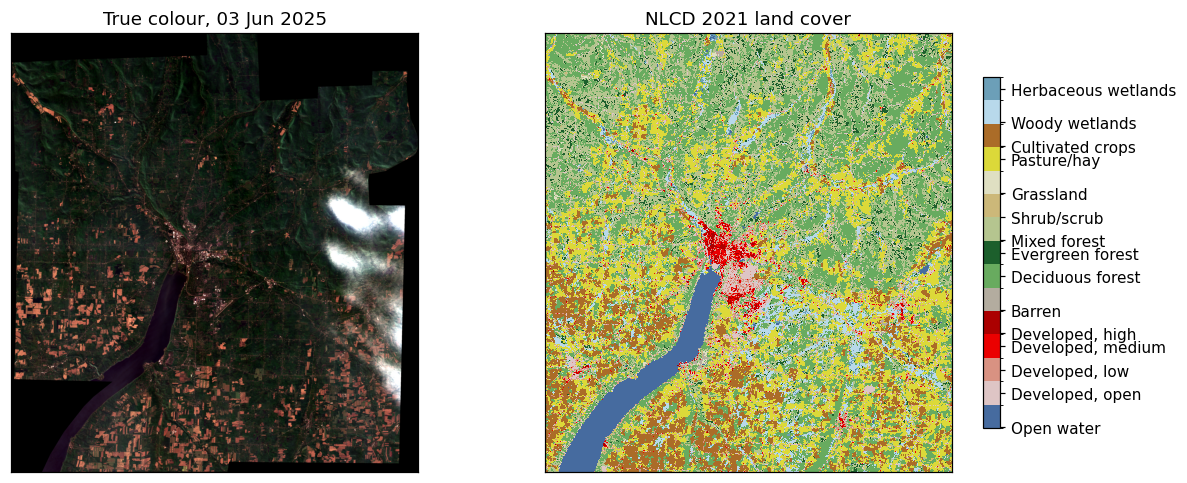

,Deciduous forest,Pasture/hay,Mixed forest,Cultivated crops,"Developed, open",Woody wetlands,Open water,"Developed, low",Evergreen forest,"Developed, medium",Herbaceous wetlands,Shrub/scrub,"Developed, high",Grassland,Barren
pixels,4366384,3567858,2519455,1516466,759041,647311,550830,415900,383464,157860,97639,94574,47736,45661,26306


In [11]:
# Map the clearest summer scene beside NLCD land cover, and count pixels by class.

# 1. Get the land cover classification (NLCD) raster for the AOI, using the first (earliest) available image in the time series
nlcd = nlcd_for(s2["red"].isel(time=0))

# 2. Flatten the NLCD array, map each pixel value to its class name using NLCD_CLASSES,
#    and count the number of pixels per class (for summary table)
counts = pd.Series(nlcd.values.ravel()) \
            .map(lambda c: NLCD_CLASSES.get(c, ("No data",))[0]) \
            .value_counts()

# 3. Find which dates are in summer (June, July, August)
is_summer = s2["time"].dt.month.isin([6, 7, 8]).values

# 4. For each date, compute the fraction of clear (usable) pixels based on the scene classification (SCL) layer
clear_frac = rs.optical.s2_scl_mask(s2["scl"]).mean(("y", "x")).values

# 5. Select the clearest summer date index (with maximum clear pixel fraction)
#    (If no summer images are clear, uses -1 as a placeholder)
summer = int(np.argmax(np.where(is_summer, clear_frac, -1)))      

# 6. Plot two side-by-side maps:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

#    a. True color RGB of Sentinel-2 for the clearest summer date
rs.viz.plot_rgb(
    s2.isel(time=summer),
    ["red", "green", "blue"],
    ax=axes[0],
    title=f"True colour, {pd.Timestamp(s2.time.values[summer]):%d %b %Y}",
    p=(1, 99)
)

#    b. Land cover map from NLCD, showing classes present in this AOI
rs.viz.plot_raster(
    nlcd.where(nlcd > 0),  # mask out "no data"
    ax=axes[1],
    categorical={k: v for k, v in NLCD_CLASSES.items() if k in np.unique(nlcd.values)},
    title="NLCD 2021 land cover"
)

# 7. Remove x/y axis ticks for clarity
for a in axes: 
    a.set_xticks([]); a.set_yticks([])  # no ticks

# 8. Adjust layout and display plots
plt.tight_layout()
plt.show()  # draw

# 9. Return/display a table summarizing the pixel counts per NLCD class
counts.to_frame("pixels").T

## Spectral signatures of the land-cover classes

Plotting mean reflectance by class across the 9 downloaded bands (on the clearest summer date)
shows the features each band captures: the chlorophyll absorption at 665 nm, the steep **red
edge** between 705 and 783 nm, the NIR plateau and the SWIR water absorption.


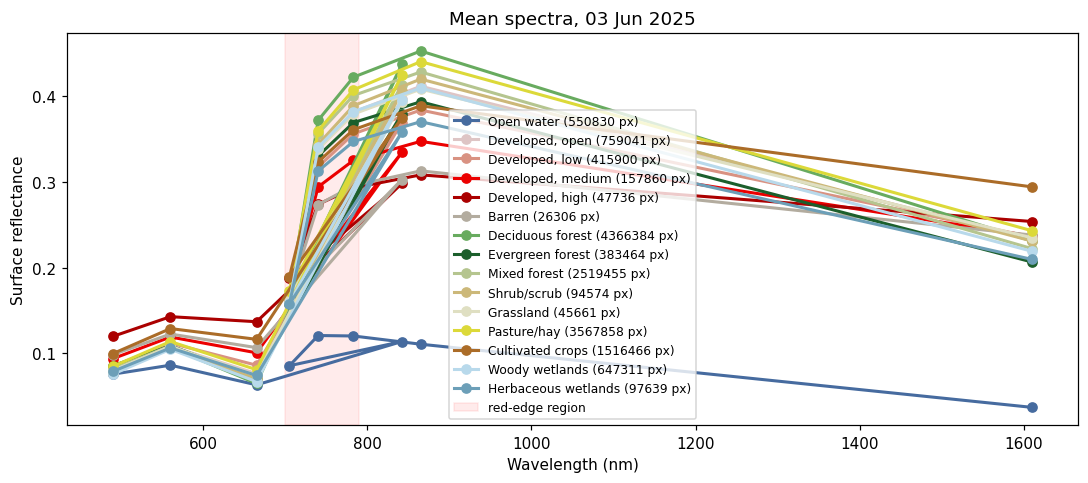

In [12]:
# This section plots the mean spectral reflectance for each major land cover class across all bands
# for the clearest summer date in the Sentinel-2 image collection. This visualizes the "spectral signatures" 
# of land cover types by showing how they reflect different wavelengths of light.

# Define the central wavelength in nanometers for each band to use as the x-axis
CENTER_NM = {
    "blue": 490, "green": 560, "red": 665,
    "rededge1": 705, "rededge2": 740, "rededge3": 783,
    "nir": 842, "nir08": 865, "swir16": 1610
}

# Scale the raw image data to surface reflectance, select the clearest summer date.
try:
    # reflectance of the chosen summer date
    refl_raw = rs.optical.scale(s2[ALL_BANDS], sensor="sentinel2").isel(time=summer)
except Exception as e:
    raise RuntimeError(f"Error scaling reflectance data: {e}")  # stop with a clear message

# Get the wavelengths (x-axis) corresponding to the bands
wl = np.array([CENTER_NM[b] for b in ALL_BANDS])

# Create a figure for plotting
fig, ax = plt.subplots(figsize=(10, 4.5))

# For each NLCD class...
for code, (name, color) in NLCD_CLASSES.items():
    # Check that the nlcd raster has "values" attribute
    if not hasattr(nlcd, 'values'):
        raise AttributeError("Expected attribute 'values' in 'nlcd'.")  # stop with a clear message
    # Create a mask for pixels that match this class code
    m = (nlcd.values == code)
    n_pixels = m.sum()  # Count matching pixels
    if n_pixels < 5000:  # too few pixels of this class
        continue  # Skip small classes
    spec = []  # mean reflectance per band
    # For each band, compute the mean reflectance value for this class
    for b in ALL_BANDS:
        band_values = refl_raw[b].values[m]  # values of this band in this class
        # Remove NaN values to avoid warnings or empty means
        band_values = band_values[~np.isnan(band_values)]
        if band_values.size == 0:  # no valid values
            spec.append(np.nan)  # store NaN
        else:
            spec.append(float(band_values.mean()))  # store the mean
    # Plot the spectral signature for this class
    ax.plot(
        wl, spec, marker="o", color=color, 
        label=f"{name} ({int(n_pixels)} px)", lw=2
    )

# Highlight the red-edge region on the spectrum
ax.axvspan(700, 790, color="red", alpha=0.08, label="red-edge region")

# Set axis labels and plot title
ax.set(
    xlabel="Wavelength (nm)",
    ylabel="Surface reflectance",
    title=f"Mean spectra, {pd.Timestamp(s2.time.values[summer]):%d %b %Y}"
)

# Show a legend and display the plot
ax.legend(fontsize=8)
plt.tight_layout()  # arrange
plt.show()  # draw

## Cloud masking

A plain STAC download of L2A ships the **Scene Classification Layer (SCL)**, a per-pixel class
(cloud, cloud shadow, snow, water, vegetation, ...) from Sen2Cor. It does not ship the raw
s2cloudless cloud *probability* that eo-learn's EOPatch format computes and stores separately;
`rs.optical.s2_scl_mask` is the mask that is actually available from a regular download, and it
is what the rest of this notebook uses.


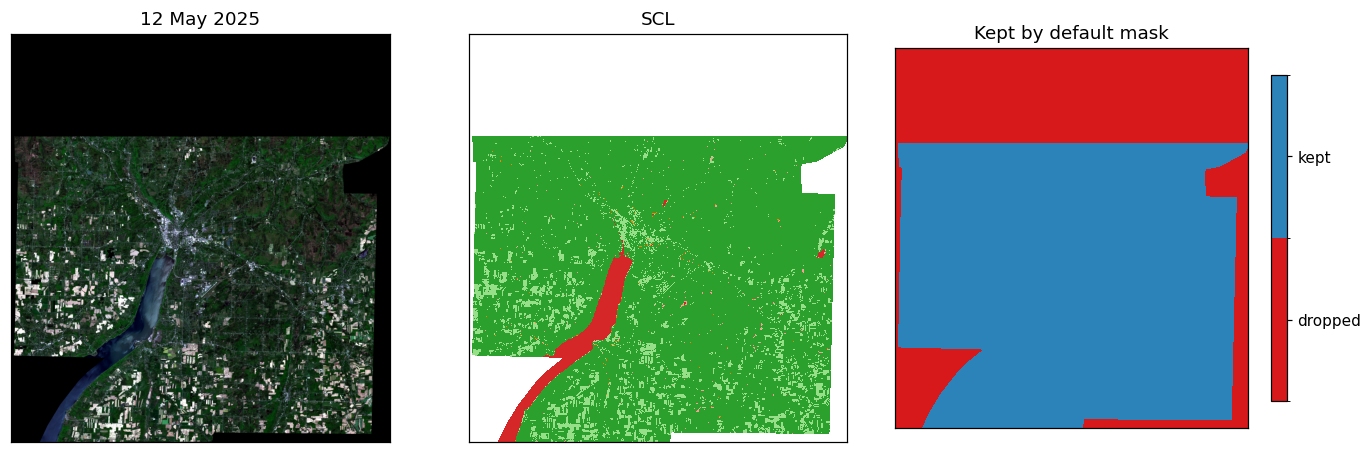

In [13]:
# Find the index (date) with the lowest fraction of valid (clear) pixels (i.e., the cloudiest date)
cloudy = int(np.argmin(clear_frac))  # Index of the image with the most clouds

# Create a figure with 3 subplots horizontally
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))

# 1. Plot the true-color (RGB) image for the cloudiest date
rs.viz.plot_rgb(
    s2.isel(time=cloudy), ["red", "green", "blue"], ax=axes[0],
    title=f"{pd.Timestamp(s2.time.values[cloudy]):%d %b %Y}", p=(1, 99)
)

# 2. Plot the Scene Classification Layer (SCL) for the same date,
# using descriptive class names and colors for each class (like cloud, shadow, etc.)
rs.viz.plot_raster(
    s2["scl"].isel(time=cloudy), ax=axes[1], title="SCL",
    categorical={i: (sentinel2.SCL_CLASSES[i], c) for i, c in zip(range(12), plt.cm.tab20.colors)},
    colorbar=False
)

# 3. Plot the result of applying the default SCL mask (which drops clouds, shadow, etc.)
# Show which pixels are 'kept' or 'dropped' after cloud masking
rs.viz.plot_raster(
    rs.optical.s2_scl_mask(s2["scl"].isel(time=cloudy)).astype(int), ax=axes[2],
    title="Kept by default mask",
    categorical={0: ("dropped", "#d7191c"), 1: ("kept", "#2b83ba")}
)

# Remove axis ticks from all subplots for cleaner visualization
for a in axes:
    a.set_xticks([])  # no x ticks
    a.set_yticks([])  # no y ticks

plt.tight_layout()  # arrange
plt.show()  # draw

### Visualizing Cloud and Scene Classification Layer (SCL) Masking


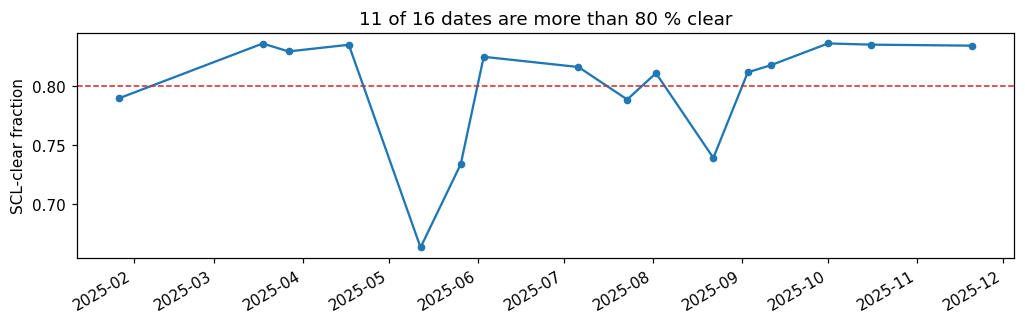

In [14]:
# Scale reflectance, mask clouds with SCL, and plot the clear fraction of each date.

# 1. Convert raw Sentinel-2 data to reflectance for all relevant bands.
refl = rs.optical.scale(s2[ALL_BANDS], sensor="sentinel2")

# 2. Generate a mask indicating which pixels are "clear" based on the Scene Classification Layer (SCL),
#    filtering out clouds, cloud shadows, and other invalid pixels.
valid = rs.optical.s2_scl_mask(s2["scl"])

# 3. Save this mask in the dataset for later use.
s2["clear"] = valid

# 4. Use the mask to create a version of the reflectance data that retains only "clear" pixels,
#    setting cloudy/invalid pixels to NaN.
clean = refl.where(s2["clear"])

# 5. Prepare to visualize how many pixels are clear in each image date.
#    'clear_frac' is assumed to be the fraction of clear pixels per time step.
#    Create a pandas Series indexed by the image acquisition dates.
frac = pd.Series(clear_frac, index=pd.to_datetime(s2.time.values))

# 6. Plot the fraction of clear pixels for each date as a line plot with points,
#    and draw a dashed horizontal reference line at the 0.8 (80%) level.
ax = frac.plot(style="o-", ms=4, figsize=(11, 3))
ax.axhline(0.8, color="C3", ls="--", lw=1)  # a reference line at 0.8

# 7. Add a label to the y-axis and a title indicating
#    how many acquisition dates have more than 80% clear pixels.
ax.set(ylabel="SCL-clear fraction", title=f"{(frac > 0.8).sum()} of {len(frac)} dates are more than 80 % clear")

plt.show()  # draw

**L2A scenes** come with the Scene Classification Layer instead. `rs.optical.s2_scl_mask` drops
no-data, saturated, shadow, cloud and cirrus classes by default:


In [16]:
# Create a DataArray representing the 12 Sentinel-2 Scene Classification Layer (SCL) classes
scl = xr.DataArray(np.arange(12, dtype="uint8"), dims="class")

# Build a DataFrame summarizing which SCL classes are kept by the default mask (snow excluded)
# versus when snow is considered valid (snow=True).
summary = pd.DataFrame({
    "SCL class": [sentinel2.SCL_CLASSES[i] for i in range(12)],
    "kept (default)": rs.optical.s2_scl_mask(scl).values,
    "kept (snow=True)": rs.optical.s2_scl_mask(scl, snow=True).values
})
summary  # show the summary table
         

,SCL class,kept (default),kept (snow=True)
0,no_data,False,False
1,saturated_defective,False,False
2,dark_area,True,True
3,cloud_shadow,False,False
4,vegetation,True,True
5,not_vegetated,True,True
6,water,True,True
7,unclassified,True,True
8,cloud_medium_probability,False,False
9,cloud_high_probability,False,False


## Red-edge indices

Chlorophyll pigments in plant leaves absorb red light very efficiently, which means the amount of reflected red light becomes very low once a canopy is dense. This causes the classic NDVI index (which uses red and near-infrared bands) to 'saturate': above a certain leaf density, increases in chlorophyll or biomass no longer result in higher NDVI values, limiting its usefulness for monitoring differences among dense canopies.

Sentinel-2, however, includes several intermediate 'red-edge' bands positioned between the red and NIR regions of the spectrum. These red-edge bands lie on the steep transitional slope between strong red absorption (due to chlorophyll) and high NIR reflectance (from leaf structure). The precise position and slope of this 'red-edge' feature are sensitive to changes in chlorophyll content and canopy nitrogen, even after NDVI has already saturated. Therefore, indices that use red-edge bands continue to capture meaningful variation in vegetation condition where NDVI no longer does.

Sentinel-2's unique band configuration thus enables a number of red-edge-based vegetation indices, making it possible to monitor plant health, chlorophyll, and nitrogen status in much greater detail in dense vegetation areas such as forests or advanced crop stages.


In [17]:
# Define a list of red-edge and vegetation index names relevant for Sentinel-2.
re_names = ["NDVI", "NDRE", "CIre", "MTCI", "IRECI", "S2REP"]

# Use the rs.optical.list_indices() function to obtain a DataFrame of available indices,
# then set 'name' as the index. Select (using .loc) only the indices in re_names,
# and only keep columns with long names, required bands, and reference citations.
cat = rs.optical.list_indices().set_index("name").loc[re_names, ["long_name", "bands", "reference"]]

# Display the resulting DataFrame summarizing the chosen red-edge indices.
cat

,long_name,bands,reference
name,,,
NDVI,Normalized Difference Vegetation Index,"nir, red",Rouse et al. 1974
NDRE,Normalized Difference Red Edge,"nir, rededge1",Barnes et al. 2000
CIre,Red-edge Chlorophyll Index,"nir, rededge1",Gitelson et al. 2003
MTCI,MERIS Terrestrial Chlorophyll Index,"rededge2, rededge1, red",Dash & Curran 2004
IRECI,Inverted Red-Edge Chlorophyll Index,"rededge3, red, rededge1, rededge2",Frampton et al. 2013
S2REP,Sentinel-2 Red-Edge Position (nm),"rededge3, red, rededge1, rededge2",Frampton et al. 2013


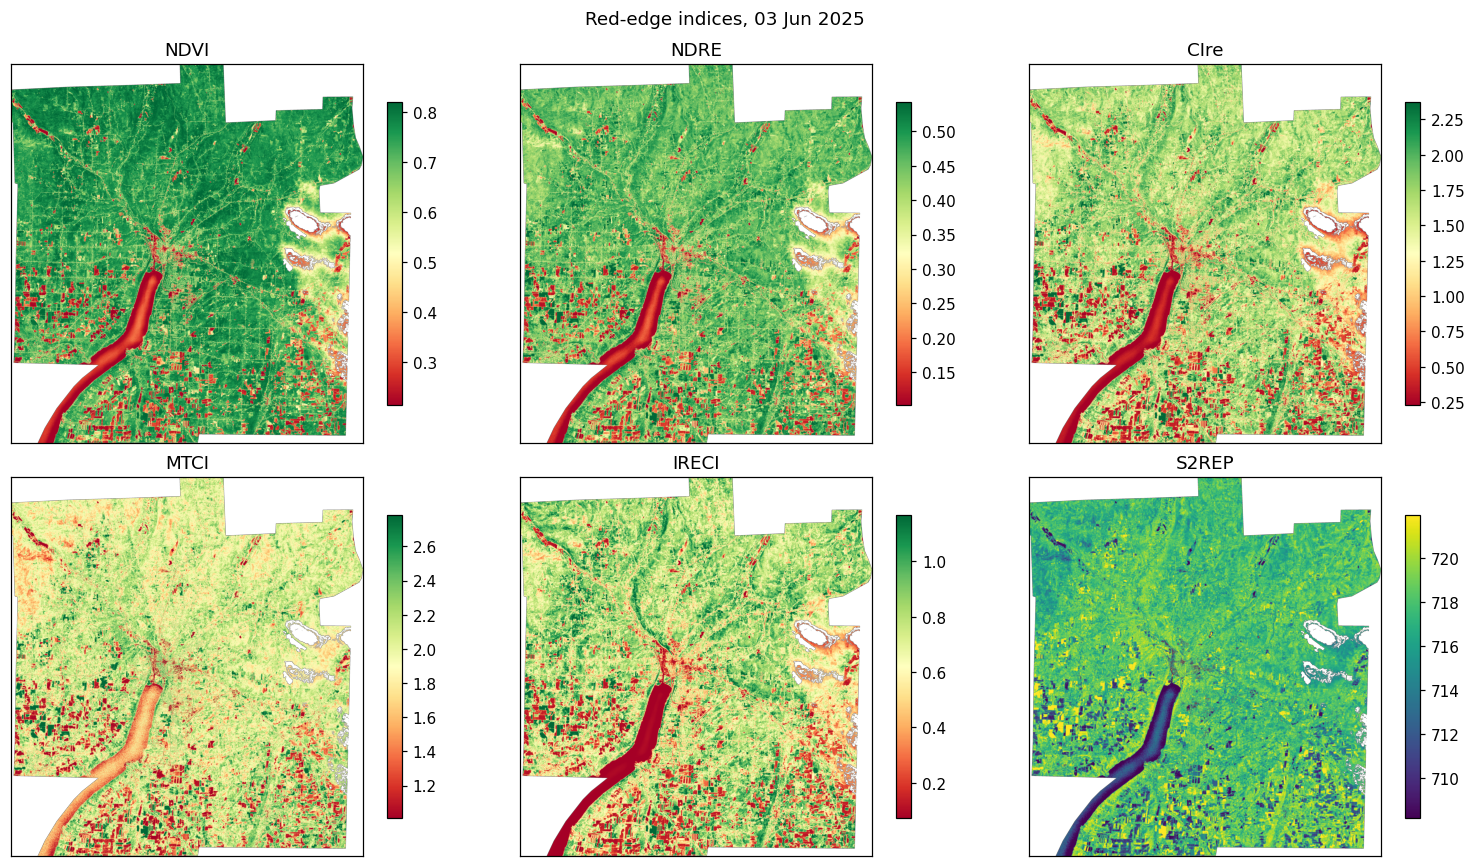

In [18]:
# Map the red-edge indices on the clearest summer date.

vi = clean.rs.index(re_names)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))  # 2 x 3 panels
for ax, n in zip(axes.ravel(), re_names):  # one red-edge index per panel
    # its map on the summer date
    rs.viz.plot_raster(vi[n].isel(time=summer), ax=ax, cmap="viridis" if n == "S2REP" else "RdYlGn", title=n)
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
# title, arrange and draw
plt.suptitle(f"Red-edge indices, {pd.Timestamp(s2.time.values[summer]):%d %b %Y}"); plt.tight_layout(); plt.show()

### Red-edge indices: visualization and saturation comparison


In [19]:
# The following code checks which vegetation indices (among NDVI, NDRE, CIre, MTCI)
# continue to show meaningful variation in areas of dense vegetation canopy,
# where NDVI typically saturates (values greater than 0.75).
# 
# 1. Filter all index layers to only retain pixels where NDVI > 0.75 ("dense canopy").
dense = vi.where(vi["NDVI"] > 0.75)

# 2. For each index, calculate the coefficient of variation
#    (standard deviation divided by the mean, in absolute value) across the dense-canopy pixels.
spread = pd.Series({
    n: float(dense[n].std() / np.abs(dense[n].mean()))
    for n in ["NDVI", "NDRE", "CIre", "MTCI"]
})

# 3. Show the coefficients of variation, rounded to 3 decimals, as a table.
#    Higher values here mean the index is less saturated and still distinguishes differences
#    under dense canopy.
spread.round(3).to_frame("coefficient of variation over dense canopy").T

,NDVI,NDRE,CIre,MTCI
coefficient of variation over dense canopy,0.091,0.135,0.304,0.289


NDVI barely varies once canopies are dense (low coefficient of variation), while NDRE and CIre
keep a much larger relative range. That remaining variation is what makes red-edge indices
useful for crop nitrogen and late-season monitoring.


## Temporal profiles and phenology

Averaging masked NDVI and NDRE per land-cover class through time reveals each class's seasonal
rhythm. With only 16 real acquisitions across the year the series is far sparser than eo-learn's
68-date Slovenia patch, so no regridding to a dense regular calendar is attempted; Whittaker
smoothing and the phenology metrics run directly on the actual, irregular acquisition dates.


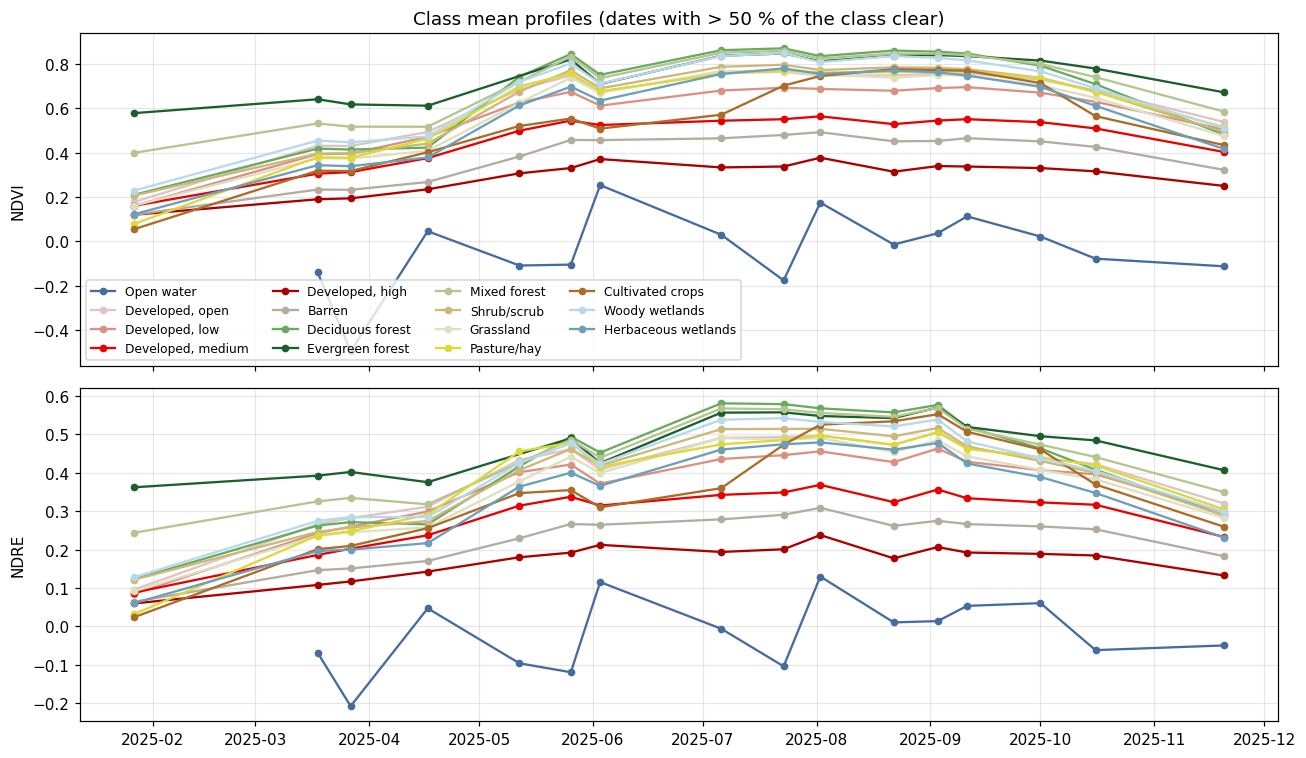

In [20]:
# This block generates time series plots of mean NDVI and NDRE values for each land cover class with sufficient area.
# 1. Create a figure with two subplots (for NDVI and NDRE), stacked vertically and sharing the x-axis (time).
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# 2. Loop through each NLCD (land cover) class. Each class has a code, a readable name, and a color for plotting.
for code, (name, color) in NLCD_CLASSES.items():
    # Create a mask (boolean array) where the land cover map 'nlcd' matches the current class code.
    m = (nlcd == code)
    # If there are fewer than 5000 pixels of this class, skip it (to only plot major classes).
    if int(m.sum()) < 5000:
        continue
    # For the two indices (NDVI and NDRE), loop through subplots and calculate the class mean time series.
    for ax, idx in zip(axes, ["NDVI", "NDRE"]):
        # Calculate the mean value of the index at each timepoint, using only pixels of this class.
        prof = vi[idx].where(m).mean(("y", "x"))
        # Identify timepoints where at least 50% of the class area has valid data (not cloud/shadow).
        ok = vi[idx].where(m).count(("y", "x")) > 0.5 * int(m.sum())
        # Plot the mean time series for this class at the OK timepoints.
        ax.plot(pd.to_datetime(s2.time.values)[ok.values], prof.values[ok.values], "o-", ms=4,
                color=color, label=name)
# 3. Label y-axes and add gridlines for readability.
for ax, idx in zip(axes, ["NDVI", "NDRE"]):
    ax.set_ylabel(idx)  # y label
    ax.grid(alpha=0.3)  # grid
# 4. Add a legend and title to the first axis. Tighten the layout and display the figure.
axes[0].legend(ncol=4, fontsize=8)
axes[0].set_title("Class mean profiles (dates with > 50 % of the class clear)")  # title of the top panel
plt.tight_layout()  # arrange
plt.show()  # draw

### Phenology mapping and metrics by land cover


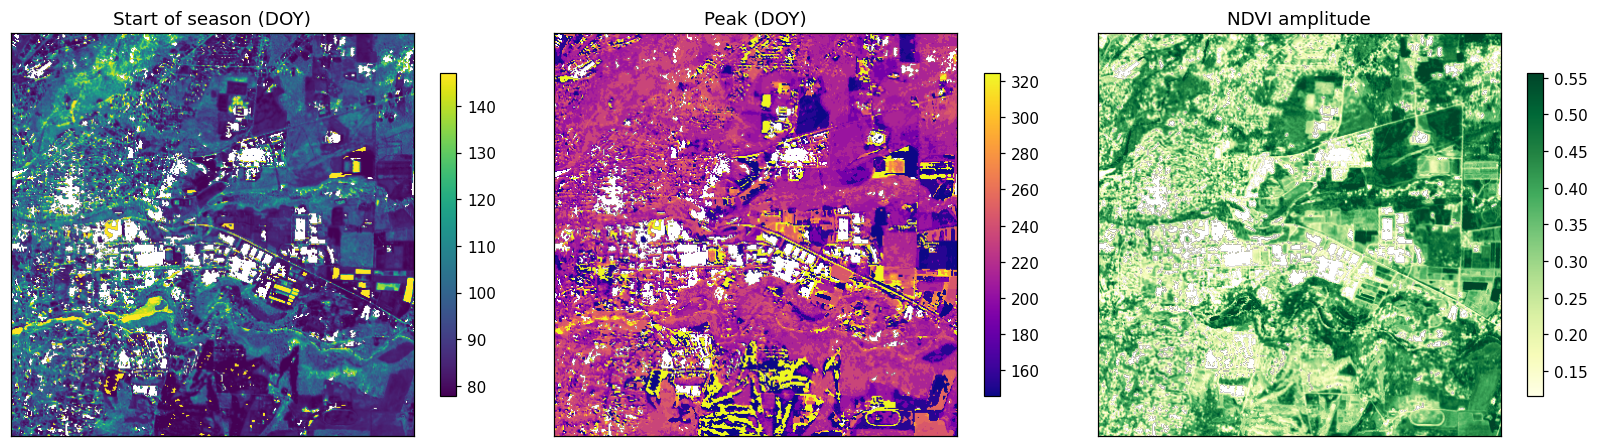

,sos,pos,eos,amplitude
Barren,92.900002,214.0,284.299988,0.3
Cultivated crops,87.099998,204.0,281.299988,0.4
Deciduous forest,98.800003,214.0,285.500000,0.4
"Developed, high",95.000000,204.0,281.100006,0.2
"Developed, low",93.300003,214.0,285.200012,0.3
"Developed, medium",95.400002,214.0,283.700012,0.2
"Developed, open",87.000000,214.0,284.500000,0.3
Evergreen forest,102.400002,234.0,285.899994,0.2
Grassland,84.300003,204.0,279.000000,0.2
Herbaceous wetlands,99.699997,234.0,286.200012,0.4


In [21]:
# This block estimates phenology metrics (seasonal vegetation timing) for a spatial window centered on the AOI, then summarizes results by land cover class.

# 1. Choose a smaller spatial window (4 km × 4 km, at 10 m resolution) for demonstration and faster processing:
ndvi = vi["NDVI"]
ny, nx = ndvi.sizes["y"], ndvi.sizes["x"]     # Get the full image dimensions.
cy, cx = ny // 2, nx // 2                     # Compute the center pixel coordinates.
window = dict(  # a zoom window
    y=slice(cy - 200, cy + 200),              # Select 400×400 pixels (roughly 4 km × 4 km) around center.
    x=slice(cx - 200, cx + 200)
)
ndvi_win = ndvi.isel(**window).load()         # Subset and load NDVI data for the window.
nlcd_win = nlcd.isel(**window)                # Subset land cover map to same window.

# 2. Smooth temporal NDVI curves at each pixel using Whittaker smoothing:
smooth = rs.timeseries.whittaker(ndvi_win, lmbda=5)

# 3. Extract phenology metrics from each pixel’s smoothed NDVI time series:
#    - 'sos' = start of season (green-up DOY)
#    - 'pos' = peak-of-season DOY
#    - 'eos' = end of season DOY
#    - 'amplitude' = difference between peak and base NDVI
pheno = rs.timeseries.phenology(
    smooth,
    threshold=0.4,         # For determining green-up/down
    min_amplitude=0.1      # Ignore pixels with very little seasonal change
)

# 4. Plot spatial maps of selected phenology metrics for the window:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k, cm in zip(  # the panels: layer, title and colour map
    axes,
    ["sos", "pos", "amplitude"],                    # Show start, peak, and amplitude
    ["viridis", "plasma", "YlGn"]
):
    rs.viz.plot_raster(  # map the layer
        pheno[k], ax=ax, cmap=cm,
        title={
            "sos": "Start of season (DOY)",
            "pos": "Peak (DOY)",
            "amplitude": "NDVI amplitude"
        }[k]
    )
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

# 5. Summarize the median phenology metrics by land cover class (in the window).
#    Groups all pixels by their class, then aggregates median sos/pos/eos/amplitude per class.
pd.DataFrame({
    k: pd.Series(pheno[k].values.ravel()).groupby(
        pd.Series(nlcd_win.values.ravel()).map(
            lambda c: NLCD_CLASSES.get(c, ("other",))[0]   # Get readable class name or "other"
        )
    ).median()
    for k in ["sos", "pos", "eos", "amplitude"]
}).round(1)

Around Ithaca, developed and cultivated pixels green up earliest (lowest start-of-season day
of year), while forest holds a later, more compressed season. Unlike the Slovenia hay meadows,
which are mown and show an early, sharp peak, this window mixes cropland, forest and suburban
land, so peak-of-season dates spread across the growing season rather than clustering on one
date. The same amplitude-threshold method (TIMESAT-style) underlies crop-type and
forest-phenology mapping from Sentinel-2 time series generally.


## Monthly composites

`rs.RasterCube` wraps the cube for period selection and temporal resampling. With only one or two
clear dates per month in the real 2025 series, a monthly "composite" is mostly a single clear
scene rather than a multi-observation median, and February has no acquisition in our 16-date set
at all. Computed on the same 4 km x 4 km window as the *Temporal profiles and phenology* section to keep the resample fast.


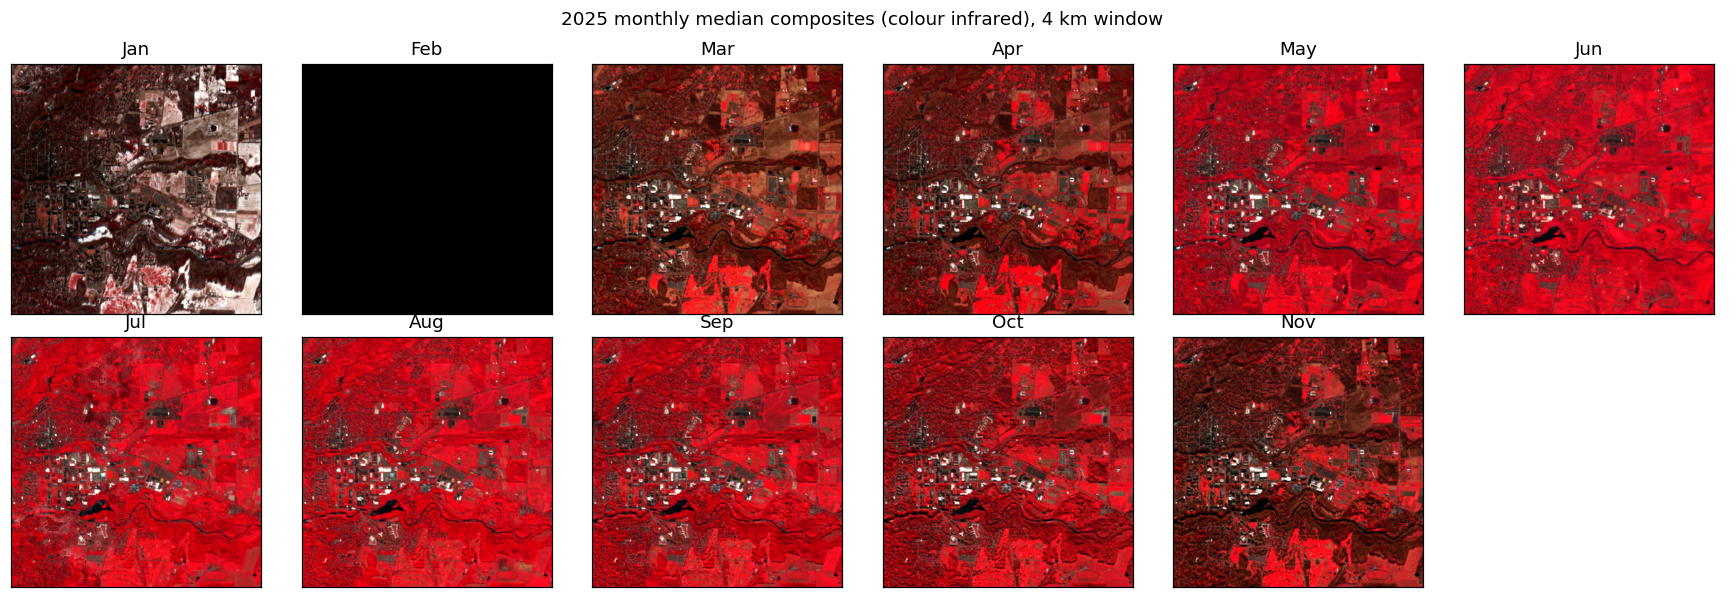

<RasterCube 11 dates × 400×400 px, bands=['blue', 'green', 'red', 'rededge1', 'nir', 'swir16'], 2025-01-01 → 2025-11-01, crs=EPSG:32618>
Months with no clear observation: ['Feb']


In [22]:
# --- Monthly Composites Processing and Visualization ---

# 1. Select the six main bands of interest and extract them from the cleaned Sentinel-2 dataset
#    (within the region/window defined by 'window'). Load the data for use.
win_ds = clean[["blue", "green", "red", "rededge1", "nir", "swir16"]].isel(**window).load()

# 2. Wrap the windowed dataset in a RasterCube, specifying that the sensor is Sentinel-2.
cube = rs.RasterCube(win_ds, sensor="sentinel2")

# 3. Select the data covering the 2025 calendar year, and resample using a monthly window
#    ("1MS" = Month Start frequency), computing the median for each month.
monthly = cube.sel_period("2025-01-01", "2025-12-31").resample("1MS", "median")

# 4. Set up a grid of subplots to display one image for each month (2 rows x 6 columns).
fig, axes = plt.subplots(2, 6, figsize=(16, 5.5))

# 5. For each available median monthly composite in the year, plot an RGB image using
#    "nir", "red", and "green" bands (false color composite to highlight vegetation).
#    The percentile scaling (p=(1, 99)) is used to stretch contrast.
for ax, (t, img) in zip(axes.ravel(), monthly.ds.groupby("time")):
    rs.viz.plot_rgb(  # the composite
        img.squeeze("time"),
        ["nir", "red", "green"],
        ax=ax,
        title=f"{pd.Timestamp(t):%b}", # Month abbreviation
        per_band=False,
        p=(1, 99)
    )
    ax.set_xticks([])  # no x ticks
    ax.set_yticks([])  # no y ticks

# 6. If there are fewer than 12 months with data, any remaining empty axes are hidden.
for ax in axes.ravel()[monthly.ds.sizes["time"]:]:
    ax.axis("off")  # hide unused panels

# 7. Set a title, adjust layout, and display the figure.
plt.suptitle("2025 monthly median composites (colour infrared), 4 km window")
plt.tight_layout()  # arrange
plt.show()  # draw

# 8. Print the summary of the monthly composites RasterCube.
print(monthly)

# 9. Print a list of months in which there was no clear (cloud-free) Sentinel-2 observation.
print(
    "Months with no clear observation:",
    [f"{pd.Timestamp(t):%b}" for t, v in zip(monthly.times, monthly.valid_fraction().values) if v == 0]
)
 

## Biophysical Processor

The Sentinel-2 Biophysical Processor (see [ATBD_S2ToolBox V2.1](https://step.esa.int/docs/extra/ATBD_S2ToolBox_V2.1.pdf))
generates Level-2B biophysical products from Level-2A (surface reflectance) data, estimating key vegetation and canopy parameters using advanced, physically-based inversion of radiative transfer models. The main output variables and relevant details are as follows:

- LAI (Leaf Area Index): Quantifies the one-sided green leaf area per unit ground area (m²/m²).
    - Definition: LAI is retrieved by inversion of the PROSAIL canopy reflectance model using top-of-canopy reflectances, primarily in red, red-edge, and NIR bands (S2: B4, B5, B6, B7, B8, B8A).
    - Range: [0, 8]
    - Use: Vegetation productivity, carbon/water cycle, agronomy.

- FAPAR (Fraction of Absorbed Photosynthetically Active Radiation): Fraction of incoming PAR (400 to 700 nm) absorbed by the canopy.
    - Definition: Estimated using PROSAIL inversion consistent with LAI retrieval.
    - Range: [0, 1]
    - Use: Photosynthesis/GPP, climate and crop models, drought monitoring.

- FCOVER (Fraction of vegetation Cover): Fraction of ground covered by green canopy.
    - Definition: Estimated via model inversion from surface reflectance, expressing the proportion of ground covered by leaves.
    - Range: [0, 1]
    - Use: Crop cover, land cover change, ecological evaluation.

- Cab (Leaf Chlorophyll Content): Total chlorophyll (a+b) content per unit leaf area (μg/cm²).
    - Definition: Derived by using red-edge and visible wavelengths (esp. B3, B4, B5, B6, B7) and inversion of PROSAIL; sensitive to variations in leaf pigmentation.
    - Range: [0, 100] μg/cm²; reported by default up to 90.
    - Use: Plant health/nutrition, stress detection, precision agriculture.

- Cw (Leaf Water Content): Equivalent water thickness of leaves, measured in g/cm².
    - Definition: Retrieved from SWIR and NIR reflectance (B8A, B11, B12), through PROSAIL model inversion.
    - Range: [0, 0.05] g/cm²
    - Use: Drought monitoring, fire risk, ecological studies.

- LAI_Cab, LAI_Cw, etc.: "Auxiliary" outputs provided as uncertainty quantification or by inverting different band combinations (see ATBD for details).

Estimation Methodology:
- Algorithms use a neural network trained on synthetic data generated from PROSAIL simulations, enabling rapid, robust pixelwise estimation of biophysical parameters from surface reflectances.
- Quality flags and uncertainties are provided in the L2B product for each variable.

Applications include: vegetation monitoring, land cover classifications, agricultural assessments, carbon and water budgets, ecological change analysis, and inputs for terrestrial models. For detailed algorithms, ranges, and band dependencies, refer to the official ATBD above.

The cells below request the five layers the Copernicus **BioPAR** service writes, via
`rs.optical.sentinel2_biophysical`. **CCC** (canopy chlorophyll content) is the canopy integral
of Cab, and **CWC** (canopy water content) is the canopy integral of Cw.


### Calculate biophysical parameters

The call below submits one Copernicus Data Space batch job per variable for Tompkins County,
1 January through 30 November 2025 (the same place and season as the cube above). Sign in with
a free [CDSE](https://dataspace.copernicus.eu) account when the browser opens. Install the
client first if it is missing: `pip install geolattice[rsense-biopar]`. GeoTIFFs already stored in
`Data/08_remote_sensing/08_02_optical/biopar_tompkins_2025/` are reused on a later run. Each job can take several minutes.


In [35]:
# Estimate LAI, FAPAR, FCOVER, CCC and CWC for Tompkins County and cache the GeoTIFFs for a single date.

s2bio = rs.optical.sentinel2_biophysical

# Set the single date for BioPAR estimation (e.g., Jan 15, 2024)
# Select a date for which free Copernicus Sentinel-2 L2A images are available 
# (the Copernicus Data Space Ecosystem only supports open/licensed imagery).
biopar_date = "2024-08-15"  # This date should have cloud free/publicly-licensed S2 images
biopar_dates = (biopar_date, biopar_date)  # start and end date (the same day)

# Set the spatial extent for Tompkins County
biopar_extent = {
    "west": -76.6393,
    "south": 42.6680,
    "east": -76.5126,
    "north": 42.7533
}

BIOPAR_DIR = DATA / "biopar_tompkins_2025_single_date"  # folder for the BioPAR outputs

info = pd.DataFrame(  # variables and their meanings as a table
    [
        (v.name, v.long_name, v.units, v.description)
        for v in (s2bio.VARIABLES[name] for name in s2bio.DEFAULT_VARIABLES)
    ],
    columns=["variable", "name", "units", "description"],
)
print(info.to_string(index=False))  # print it
print("Extent:", biopar_extent)  # the extent
print("Date:", biopar_date)  # the date


def _biopar_tifs(name):  # GeoTIFFs already downloaded for one variable
    folder = BIOPAR_DIR / name  # its folder
    return sorted(folder.glob("*.tif")) + sorted(folder.glob("*.tiff"))  # .tif and .tiff files


# variables without a downloaded GeoTIFF
missing = [name for name in s2bio.DEFAULT_VARIABLES if not _biopar_tifs(name)]
if missing:  # some are missing
    print("Submitting BioPAR jobs for:", ", ".join(missing))  # report them
    try:
        biopar_paths = s2bio.estimate(  # run the BioPAR processing for those variables
            biopar_extent,
            biopar_dates,
            variables=missing,
            out_dir=BIOPAR_DIR,
        )
    except ImportError as exc:
        biopar_paths = {}  # no results
        print(exc)  # explain why
    else:
        for name, files in biopar_paths.items():  # every downloaded variable
            print(f"{name}: downloaded {len(files)} file(s)")  # how many files
else:
    print("Using cached BioPAR GeoTIFFs in", BIOPAR_DIR.resolve())  # everything is cached

for name in s2bio.DEFAULT_VARIABLES:  # every variable
    print(f"{name}: {len(_biopar_tifs(name))} GeoTIFF(s)")  # number of GeoTIFFs

variable                                                     name   units                                                       description
     LAI                                          Leaf area index  m2 m-2 Half the total green canopy area per unit horizontal ground area.
   FAPAR Fraction of absorbed photosynthetically active radiation       1                Fraction of incoming PAR absorbed by green leaves.
  FCOVER                             Fraction of vegetation cover       1                   Fraction of ground covered by green vegetation.
     CCC                               Canopy chlorophyll content ug cm-2                           Total chlorophyll per unit ground area.
     CWC                                     Canopy water content  g cm-2                                  Water mass per unit ground area.
Extent: {'west': -76.6393, 'south': 42.668, 'east': -76.5126, 'north': 42.7533}
Date: 2024-08-15
Submitting BioPAR jobs for: LAI, FAPAR, FCOVER, CCC, CWC
Authen

### Maps

One GeoTIFF per variable, all for 15 August 2024, in `Data/08_remote_sensing/08_02_optical/biopar_tompkins_2025_single_date/`.
LAI is drawn from 0 to 8, and FAPAR and FCOVER from 0 to 1. CCC and CWC start at 0 and stop at
the 98th percentile, so a few extreme pixels do not flatten the map.


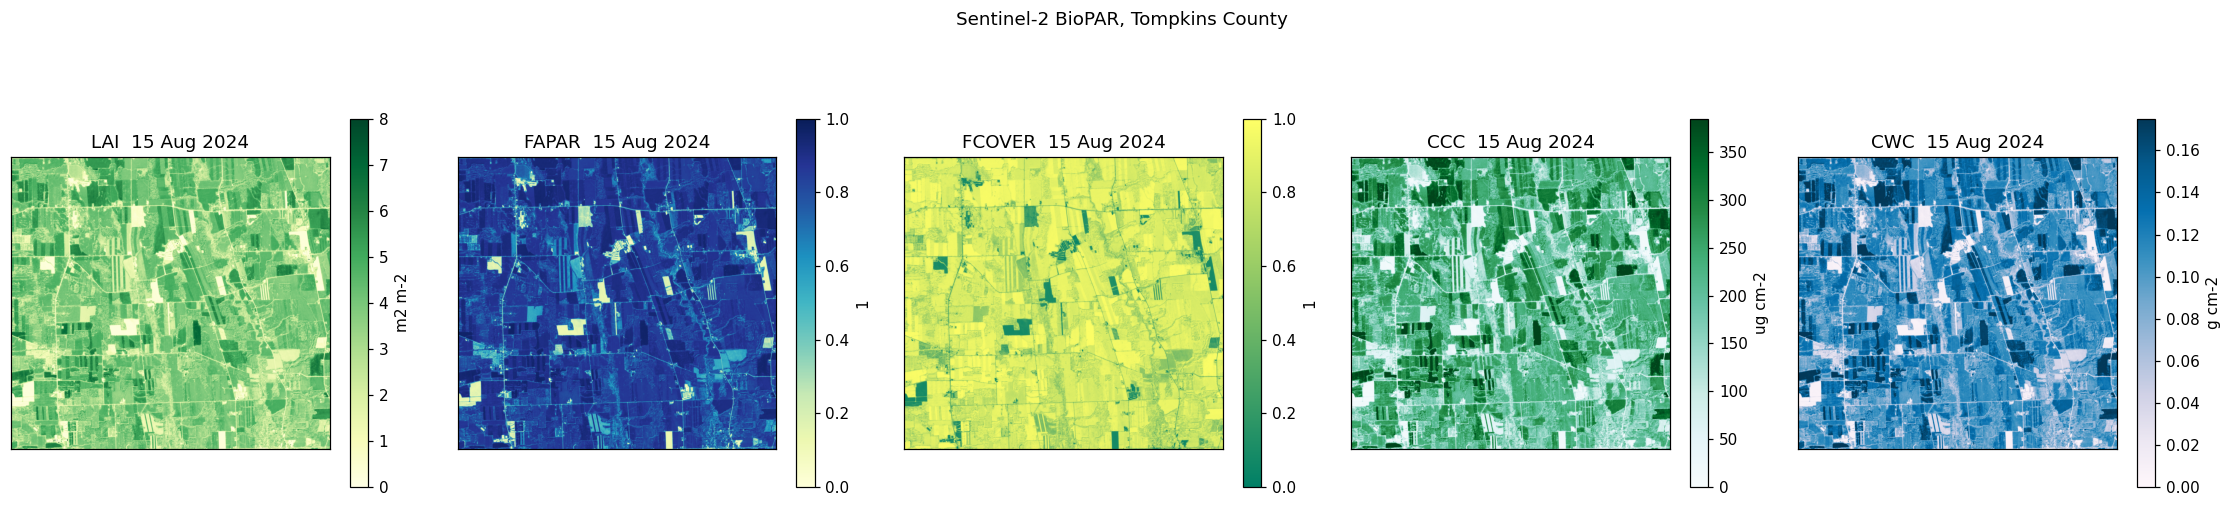

In [41]:
# Map every BioPAR GeoTIFF cached for the single date.

BIOPAR_DIR = DATA / "biopar_tompkins_2025_single_date"
s2bio = rs.optical.sentinel2_biophysical  # the GeoLattice BioPAR module

CMAP = {  # a colour map per variable
    "LAI": "YlGn",
    "FAPAR": "YlGnBu",
    "FCOVER": "summer",
    "CCC": "BuGn",
    "CWC": "PuBu",
}
LIMITS = {"LAI": (0, 8), "FAPAR": (0, 1), "FCOVER": (0, 1)}  # fixed colour limits for the known variables

names = [  # variables with GeoTIFFs on disk
    name for name in s2bio.DEFAULT_VARIABLES
    if list((BIOPAR_DIR / name).glob("*.tif")) or list((BIOPAR_DIR / name).glob("*.tiff"))
]
if not names:  # nothing to show
    print("No GeoTIFFs in", BIOPAR_DIR.resolve())  # say so
else:
    # one panel per variable
    fig, axes = plt.subplots(1, len(names), figsize=(4.1 * len(names), 4.8), squeeze=False)
    for ax, name in zip(axes[0], names):  # every variable
        da = s2bio.read(BIOPAR_DIR / name, variable=name)  # read its GeoTIFF(s)
        # the acquisition time, if stored
        stamp = pd.Timestamp(str(da.time.values[0])) if "time" in da.dims else None
        if "time" in da.dims:  # a time dimension:
            da = da.isel(time=0)  # take the first date
        if name in LIMITS:  # known variable:
            vmin, vmax = LIMITS[name]  # fixed limits
        else:
            finite = np.asarray(da.values, dtype="float64")  # otherwise derive limits from the data
            finite = finite[np.isfinite(finite)]  # finite values only
            # 0 to the 98th percentile
            vmin, vmax = (0.0, float(np.percentile(finite, 98))) if finite.size else (None, None)
        rs.viz.plot_raster(  # map the variable
            da,
            ax=ax,
            cmap=CMAP[name],
            vmin=vmin,
            vmax=vmax,
            title=name if stamp is None else f"{name}  {stamp:%d %b %Y}",
            robust=False,
        )
        ax.set_xticks([])  # no x ticks
        ax.set_yticks([])  # no y ticks
    fig.suptitle("Sentinel-2 BioPAR, Tompkins County", y=1.02)  # overall title
    fig.tight_layout()  # arrange
    plt.show()  # draw

## Summary, exercises and references

**Key ideas**

- Sentinel-2 gives 10-20 m imagery every 2-5 days with three red-edge bands.
- Use L2A for analysis; remember the -1000 offset for scenes processed after 25 January 2022.
- A plain download only ships the SCL class layer; a small threshold plus `s2_scl_mask` makes a
  reliable cloud and shadow mask without a separate cloud-probability product.
- Red-edge indices saturate less than NDVI over dense canopies.
- Class profiles, Whittaker smoothing and phenology metrics work directly on real, irregular
  acquisition dates; a dense regular calendar is not required.
- The SNAP biophysical processor (Weiss and Baret 2016), exposed as Copernicus BioPAR, turns L2A
  reflectance into LAI, FAPAR, FCOVER, canopy chlorophyll (CCC) and canopy water (CWC).

**`geolattice.rsense` functions used:** `rs.optical.scale`, `rs.optical.load_sentinel2/load_hls`,
`geolattice.rsense.get_images.search_images/get_images`, `rs.optical.guess_sensor`,
`rs.optical.s2_scl_mask`, `.rs.index`, `rs.viz.plot_rgb/plot_raster`,
`rs.timeseries.whittaker/phenology`, `rs.RasterCube`,
`rs.optical.sentinel2_biophysical.estimate/read`.

**Next:** Notebook 07_02_06 works with Sentinel-3.


**Exercises**

1. Change the SCL exclude list (snow=True, or dark=True) and see how the clear fraction and class
   profiles change.
2. Compare NDVI computed with `nir` (broad, B08) and `nir08` (narrow, B8A) using
   `.rs.index("NDVI", bands={"nir": "nir08"})`.
3. Map the date of maximum NDRE for 2025 and compare it with the date of maximum NDVI.
4. Train a random forest (the classification chapter, 07_08) on the monthly composites to predict the NLCD land-cover map.
5. Pick a different county from `NY_County_GCS.shp` and repeat the download, cloud-masking, signature, red-edge and phenology sections for it.
6. Compare the date of maximum spatial-mean LAI from the *Biophysical Processor* section with the date of maximum NDVI
   from the *Temporal profiles and phenology* section. Residual cloud in a single BioPAR scene can move the LAI peak.
